# 1. Your browser is an R laboratory

**Question:** Can a small, reproducible spatial experiment run without a server-side R session?
**Objectives:** run cells, generate a spatial field, audit values, and record the runtime.
**Prerequisites:** basic vectors and data frames. **Time:** 20 minutes.

Select **R (webR)**, then use **Run > Run All Cells**. First startup downloads webR;
later package installations also need a network connection. Your working files live in browser
storage. Download important notebooks with the file browser's Download command; clearing site
data can erase your changes. Restarting the kernel clears R objects.

This book uses fictional observations and generated geometry throughout. Nothing in a map
describes a real population or place. Base R graphics keep the core small and work with the
kernel's PNG display. Optional packages are extensions, clearly reported when unavailable.

[Open this chapter in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=01-browser-laboratory.ipynb)

In [1]:
# Project: JupyterLite-R | Chapter: 01-browser-laboratory
# Purpose: reproducible browser-based spatial simulation.
# Author: project contributors with Codex; contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: none | Outputs: inline plots and tables.
# Dependencies: base R; webR in Lab. Change log: initial original lesson.
set.seed(20261116)
options(webr.fig.width = 9, webr.fig.height = 6)
stations <- expand.grid(easting_km = seq(0, 10, 2), northing_km = seq(0, 8, 2))
stations$id <- sprintf("S%02d", seq_len(nrow(stations)))
stations$signal <- with(stations, 15 + 2 * sin(easting_km / 3) + northing_km / 2) +
  rnorm(nrow(stations), sd = 0.35)
stopifnot(nrow(stations) == 30, !anyDuplicated(stations$id), all(is.finite(stations$signal)))
head(stations)

  easting_km northing_km  id   signal
1          0           0 S01 14.25167
2          2           0 S02 16.09989
3          4           0 S03 16.93324
4          6           0 S04 16.13738
5          8           0 S05 15.97381
6         10           0 S06 14.52330


## Make the spatial pattern visible
Each point is a fictional instrument; coordinates are local kilometres with no Earth CRS.
Color represents a simulated signal in arbitrary units. The coordinate grid is complete:
there is no missingness, sampling weight, or real-world inference in this experiment.

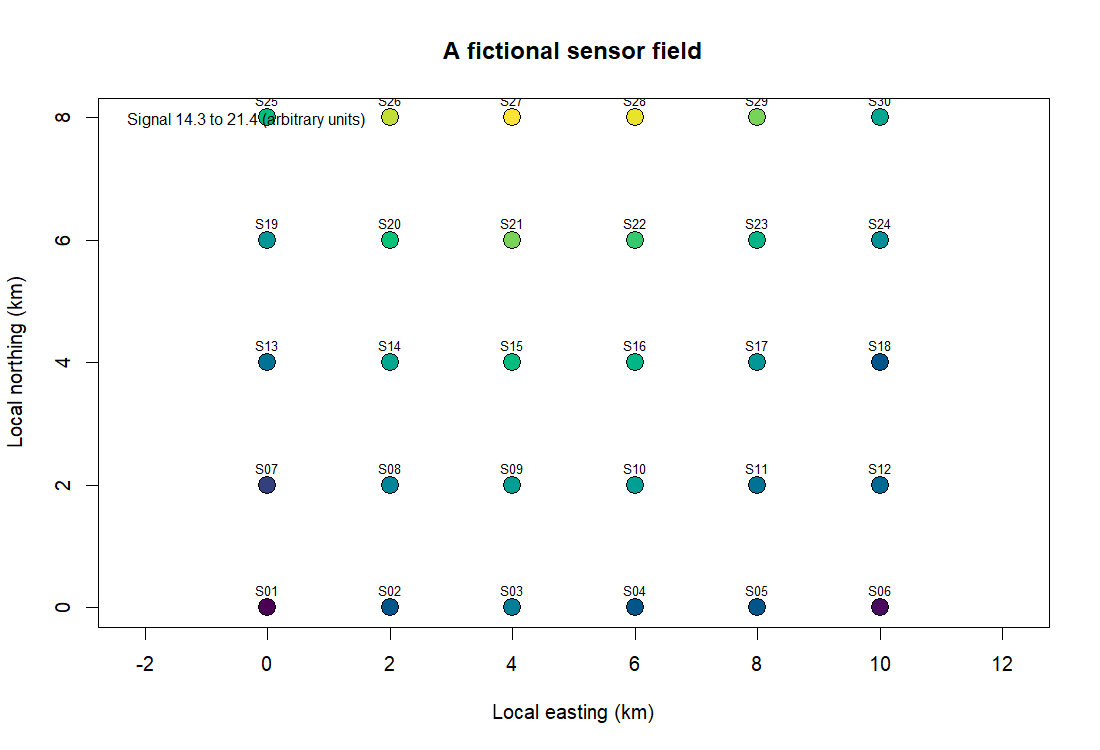

In [2]:
colors <- hcl.colors(30, "Viridis")
bins <- cut(stations$signal, breaks = 30, include.lowest = TRUE, labels = FALSE)
plot(northing_km ~ easting_km, data = stations, asp = 1, pch = 21,
     bg = colors[bins], cex = 2, xlab = "Local easting (km)", ylab = "Local northing (km)",
     main = "A fictional sensor field")
text(stations$easting_km, stations$northing_km, stations$id, pos = 3, cex = 0.65)
legend("topleft", legend = sprintf("Signal %.1f to %.1f (arbitrary units)",
       min(stations$signal), max(stations$signal)), bty = "n", cex = 0.8)

**Read the figure:** the northward gradient was built into the generator. A visible pattern
is evidence about this simulation, not a discovery about the Earth. The printed data frame
is a text alternative to color. Change the noise standard deviation to see the pattern weaken.

## Package setup is a separate decision
To install a package intentionally in Lab, run `webr::install("RColorBrewer")` in a new cell.
Browser packages must be available as compatible WebAssembly binaries. Installing a desktop
CRAN binary does not make it a browser package. Chapters check packages with `requireNamespace()`
and print a skip message if an extension is unavailable; base R activities still run.

In [3]:
packages <- c("RColorBrewer", "sf", "terra", "spdep", "micromapST", "ggplot2")
availability <- data.frame(package = packages,
  installed = vapply(packages, requireNamespace, logical(1), quietly = TRUE))
print(availability, row.names = FALSE)
sessionInfo()

      package installed
 RColorBrewer     FALSE
           sf     FALSE
        terra     FALSE
        spdep     FALSE
   micromapST     FALSE
      ggplot2     FALSE
R version 4.6.0 (2026-04-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26100)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] C
system code page: 65001

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
[1] compiler_4.6.0


## Practice and check
1. Double the grid resolution. How does the number of observations change?
2. Replace the seed, rerun, then restore it. Which quantities remain unchanged?
3. Download the notebook, restart the kernel, and rerun from the top.
**Checkpoint:** the original grid has 30 unique stations; coordinates repeat in each direction,
but station IDs do not. A seed reproduces draws within a compatible R RNG/runtime setup.

## Sources
[webR package installation](https://docs.r-wasm.org/webr/latest/packages.html);
[R kernel](https://github.com/r-wasm/jupyterlite-webr-kernel);
[R graphics reference](https://stat.ethz.ch/R-manual/R-devel/library/graphics/html/00Index.html).
Prose, code, and simulated observations in this lesson are original.